# Image Generation Using WGAN-GP on Oxford Flowers 102


# Task 1: Install and Import Required Libraries



In [1]:
!pip -q install scipy tqdm

import os
import random
import math
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.utils as vutils
from torchvision.datasets import Flowers102
from torch.utils.data import DataLoader, ConcatDataset

from tqdm.auto import tqdm

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128


# Task 2: Set Random Seeds and Select Device



In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


# Task 3: Define Hyperparameters



In [3]:
IMAGE_SIZE = 64
CHANNELS_IMG = 3
Z_DIM = 128
FEATURES_G = 64
FEATURES_D = 64

# Training settings
BATCH_SIZE = 64
NUM_EPOCHS = 5            # Increase to 20+ for better quality
LR = 1e-4
BETA1 = 0.0
BETA2 = 0.9
N_CRITIC = 5             # Number of critic updates per generator update
LAMBDA_GP = 10.0          # Gradient penalty strength

# Visualization
NUM_FIXED_SAMPLES = 64
DATA_ROOT = "./data"
OUTPUT_DIR = Path("./wgan_gp_flowers_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Hyperparameters loaded.")

Hyperparameters loaded.


# Task 4: Load and Preprocess Oxford Flowers 102


In [4]:
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Use all available splits to give the GAN more training images.
train_data = Flowers102(root=DATA_ROOT, split="train", download=True, transform=transform)
val_data = Flowers102(root=DATA_ROOT, split="val", download=True, transform=transform)
test_data = Flowers102(root=DATA_ROOT, split="test", download=True, transform=transform)

dataset = ConcatDataset([train_data, val_data, test_data])

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True if device.type == "cuda" else False,
    drop_last=True
)

print("Total images:", len(dataset))
print("Number of batches:", len(dataloader))


100%|██████████| 345M/345M [00:15<00:00, 21.9MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.95MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 39.9MB/s]


Total images: 8189
Number of batches: 127


# Task 5: Visualize Real Images

Before training a GAN, we should inspect the training images.



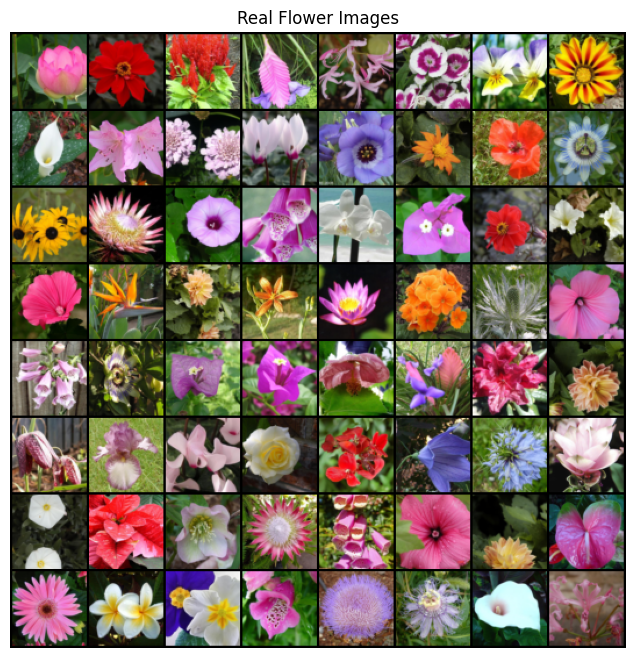

In [5]:
def denormalize(img_tensor):
    """
    Convert image tensor from [-1, 1] to [0, 1] for visualization.
    """
    return (img_tensor + 1) / 2

real_batch = next(iter(dataloader))
real_images = real_batch[0].to(device)

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Real Flower Images")
grid = vutils.make_grid(denormalize(real_images[:64].cpu()), nrow=8, padding=2)
plt.imshow(np.transpose(grid, (1, 2, 0)))
plt.show()

# Task 6: Define the Generator



In [6]:
class Generator(nn.Module):
    def __init__(self, z_dim, channels_img, features_g):
        super().__init__()
        self.net = nn.Sequential(
            # Input: N x z_dim x 1 x 1
            self._block(z_dim, features_g * 8, 4, 1, 0),           # 4 x 4
            self._block(features_g * 8, features_g * 4, 4, 2, 1),  # 8 x 8
            self._block(features_g * 4, features_g * 2, 4, 2, 1),  # 16 x 16
            self._block(features_g * 2, features_g, 4, 2, 1),      # 32 x 32
            nn.ConvTranspose2d(
                features_g,
                channels_img,
                kernel_size=4,
                stride=2,
                padding=1
            ),  # 64 x 64
            nn.Tanh()
        )

    def _block(self, in_channels, out_channels, kernel_size, stride, padding):
        return nn.Sequential(
            nn.ConvTranspose2d(
                in_channels,
                out_channels,
                kernel_size,
                stride,
                padding,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(True)
        )

    def forward(self, x):
        return self.net(x)


# Task 7: Define the Critic

In WGAN-GP, the discriminator is usually called a **critic**.

Important difference from a standard GAN discriminator:

- Standard GAN discriminator outputs a probability using `Sigmoid()`.
- WGAN-GP critic outputs a real-valued score.
- Therefore, the critic should **not** use a final `Sigmoid()`.



In [7]:
class Critic(nn.Module):
    def __init__(self, channels_img, features_d):
        super().__init__()
        self.net = nn.Sequential(
            # Input: N x channels_img x 64 x 64
            nn.Conv2d(channels_img, features_d, kernel_size=4, stride=2, padding=1),  # 32 x 32
            nn.LeakyReLU(0.2, inplace=True),
            self._block(features_d, features_d * 2, 4, 2, 1),      # 16 x 16
            self._block(features_d * 2, features_d * 4, 4, 2, 1),  # 8 x 8
            self._block(features_d * 4, features_d * 8, 4, 2, 1),  # 4 x 4
            nn.Conv2d(
                features_d * 8,
                1,
                kernel_size=4,
                stride=1,
                padding=0
            )  # 1 x 1
        )

    def _block(self, in_channels, out_channels, kernel_size, stride, padding):
        # We avoid BatchNorm in the critic for WGAN-GP.
        return nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size,
                stride,
                padding,
                bias=False
            ),
            nn.InstanceNorm2d(out_channels, affine=True),
            nn.LeakyReLU(0.2, inplace=True)
        )

    def forward(self, x):
        return self.net(x).view(-1)

# Task 8: Initialize Model Weights



In [8]:
def initialize_weights(model):
    """
    Initialize Conv, ConvTranspose, BatchNorm, and InstanceNorm layers.
    """
    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.normal_(module.weight.data, 0.0, 0.02)
        elif isinstance(module, (nn.BatchNorm2d, nn.InstanceNorm2d)):
            if module.weight is not None:
                nn.init.normal_(module.weight.data, 1.0, 0.02)
            if module.bias is not None:
                nn.init.constant_(module.bias.data, 0)

generator = Generator(Z_DIM, CHANNELS_IMG, FEATURES_G).to(device)
critic = Critic(CHANNELS_IMG, FEATURES_D).to(device)

initialize_weights(generator)
initialize_weights(critic)

print(generator)
print(critic)

Generator(
  (net): Sequential(
    (0): Sequential(
      (0): ConvTranspose2d(128, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
      (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): Sequential(
      (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (3): Sequential(
      (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=Tr

# Task 9: Test Model Shapes



In [9]:
test_noise = torch.randn(8, Z_DIM, 1, 1).to(device)
test_fake = generator(test_noise)
test_score = critic(test_fake)

print("Noise shape:", test_noise.shape)
print("Generated image shape:", test_fake.shape)
print("Critic score shape:", test_score.shape)


Noise shape: torch.Size([8, 128, 1, 1])
Generated image shape: torch.Size([8, 3, 64, 64])
Critic score shape: torch.Size([8])


# Task 10: Implement Gradient Penalty

The gradient penalty enforces the 1-Lipschitz constraint required by WGAN.

It is computed on images interpolated between real and fake samples.

The penalty term is:

`lambda_gp * E[(||grad critic(interpolated)||_2 - 1)^2]`



In [10]:
def gradient_penalty(critic, real, fake, device):
    """
    Compute WGAN-GP gradient penalty.

    Args:
        critic: critic network
        real: real images, shape (N, C, H, W)
        fake: generated images, shape (N, C, H, W)
        device: CPU or CUDA

    Returns:
        scalar gradient penalty
    """
    batch_size, c, h, w = real.shape

    epsilon = torch.rand(batch_size, 1, 1, 1, device=device)
    interpolated = epsilon * real + (1 - epsilon) * fake
    interpolated.requires_grad_(True)

    mixed_scores = critic(interpolated)

    gradients = torch.autograd.grad(
        inputs=interpolated,
        outputs=mixed_scores,
        grad_outputs=torch.ones_like(mixed_scores),
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]

    gradients = gradients.view(batch_size, -1)
    gradient_norm = gradients.norm(2, dim=1)

    gp = torch.mean((gradient_norm - 1) ** 2)
    return gp

# Task 11: Define Optimizers



In [11]:
optimizer_g = optim.Adam(generator.parameters(), lr=LR, betas=(BETA1, BETA2))
optimizer_c = optim.Adam(critic.parameters(), lr=LR, betas=(BETA1, BETA2))

fixed_noise = torch.randn(NUM_FIXED_SAMPLES, Z_DIM, 1, 1).to(device)

print("Optimizers ready.")

Optimizers ready.


# Task 12: WGAN-GP Loss Functions

For WGAN-GP, the critic tries to assign higher scores to real images and lower scores to fake images.

Critic loss:

`loss_critic = -(mean(C(real)) - mean(C(fake))) + lambda_gp * gradient_penalty`

This is commonly written as:

`loss_critic = mean(C(fake)) - mean(C(real)) + lambda_gp * gradient_penalty`

Generator loss:

`loss_generator = -mean(C(fake))`


# Task 13: Train WGAN-GP

Training loop summary:

1. Train the critic `N_CRITIC` times.
2. Train the generator once.
3. Save losses.
4. Periodically display generated samples.


In [12]:
generator.train()
critic.train()

g_losses = []
c_losses = []

start_time = time.time()

for epoch in range(NUM_EPOCHS):
    progress_bar = tqdm(dataloader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}")

    for batch_idx, (real, _) in enumerate(progress_bar):
        real = real.to(device)
        current_batch_size = real.size(0)

        # -------------------------
        # Train Critic
        # -------------------------
        for _ in range(N_CRITIC):
            noise = torch.randn(current_batch_size, Z_DIM, 1, 1).to(device)
            fake = generator(noise)

            critic_real = critic(real)
            critic_fake = critic(fake.detach())

            gp = gradient_penalty(critic, real, fake.detach(), device)

            loss_critic = (
                torch.mean(critic_fake)
                - torch.mean(critic_real)
                + LAMBDA_GP * gp
            )

            critic.zero_grad(set_to_none=True)
            loss_critic.backward()
            optimizer_c.step()

        # -------------------------
        # Train Generator
        # -------------------------
        noise = torch.randn(current_batch_size, Z_DIM, 1, 1).to(device)
        fake = generator(noise)
        gen_fake = critic(fake)

        loss_generator = -torch.mean(gen_fake)

        generator.zero_grad(set_to_none=True)
        loss_generator.backward()
        optimizer_g.step()

        g_losses.append(loss_generator.item())
        c_losses.append(loss_critic.item())

        progress_bar.set_postfix({
            "Loss C": f"{loss_critic.item():.4f}",
            "Loss G": f"{loss_generator.item():.4f}"
        })

    # Save generated sample grid after each epoch
    generator.eval()
    with torch.no_grad():
        fake_samples = generator(fixed_noise).detach().cpu()
        sample_grid = vutils.make_grid(denormalize(fake_samples), nrow=8, padding=2)
        vutils.save_image(sample_grid, OUTPUT_DIR / f"generated_epoch_{epoch+1:03d}.png")
    generator.train()

elapsed = time.time() - start_time
print(f"Training completed in {elapsed/60:.2f} minutes.")

Epoch 1/5:   0%|          | 0/127 [00:00<?, ?it/s]

Epoch 2/5:   0%|          | 0/127 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c0fd6a2ee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c0fd6a2ee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Epoch 3/5:   0%|          | 0/127 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c0fd6a2ee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c0fd6a2ee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Epoch 4/5:   0%|          | 0/127 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c0fd6a2ee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
      ^ ^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c0fd6a2ee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Epoch 5/5:   0%|          | 0/127 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c0fd6a2ee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c0fd6a2ee80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Training completed in 6.55 minutes.


# Task 14: Plot Generator and Critic Losses


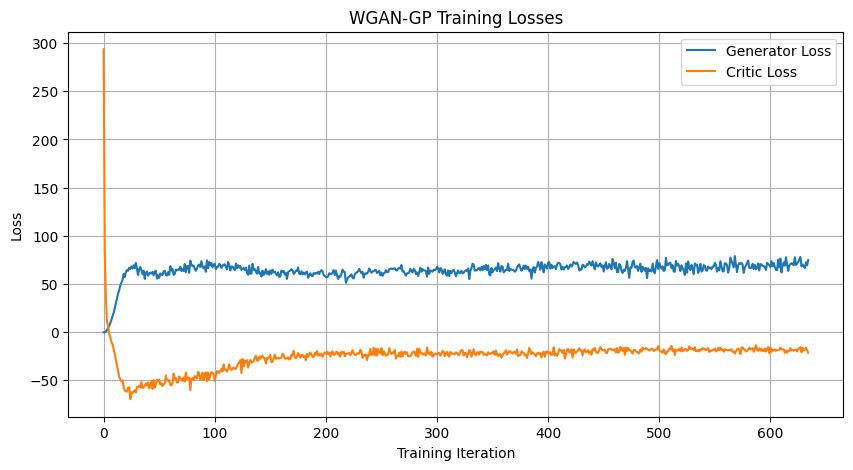

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(g_losses, label="Generator Loss")
plt.plot(c_losses, label="Critic Loss")
plt.xlabel("Training Iteration")
plt.ylabel("Loss")
plt.title("WGAN-GP Training Losses")
plt.legend()
plt.grid(True)
plt.show()

# Task 15: Generate New Flower Images


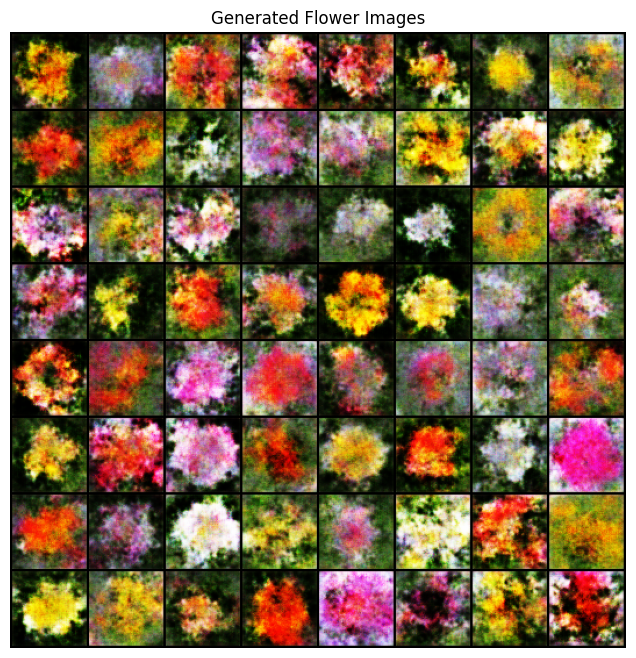

Saved final image grid to: wgan_gp_flowers_outputs/final_generated_flowers.png


In [14]:
generator.eval()

with torch.no_grad():
    noise = torch.randn(64, Z_DIM, 1, 1).to(device)
    generated_images = generator(noise).detach().cpu()

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Generated Flower Images")
grid = vutils.make_grid(denormalize(generated_images), nrow=8, padding=2)
plt.imshow(np.transpose(grid, (1, 2, 0)))
plt.show()

vutils.save_image(grid, OUTPUT_DIR / "final_generated_flowers.png")
print("Saved final image grid to:", OUTPUT_DIR / "final_generated_flowers.png")


# Task 16: Compare Real and Generated Images


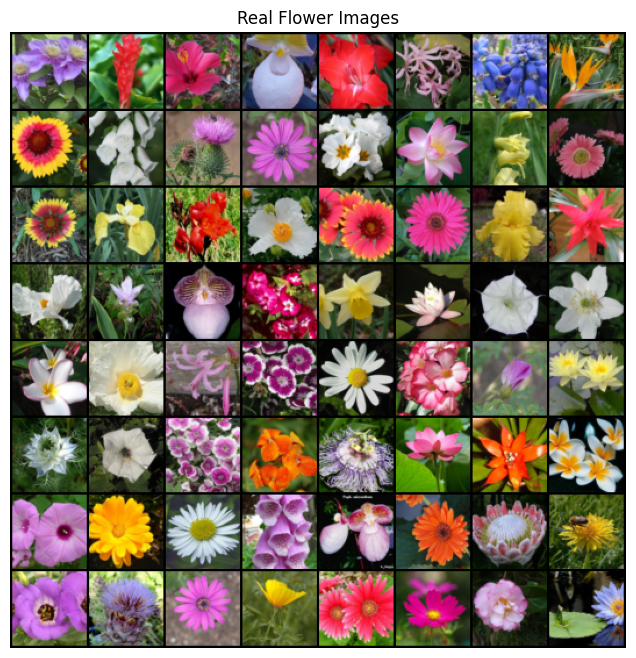

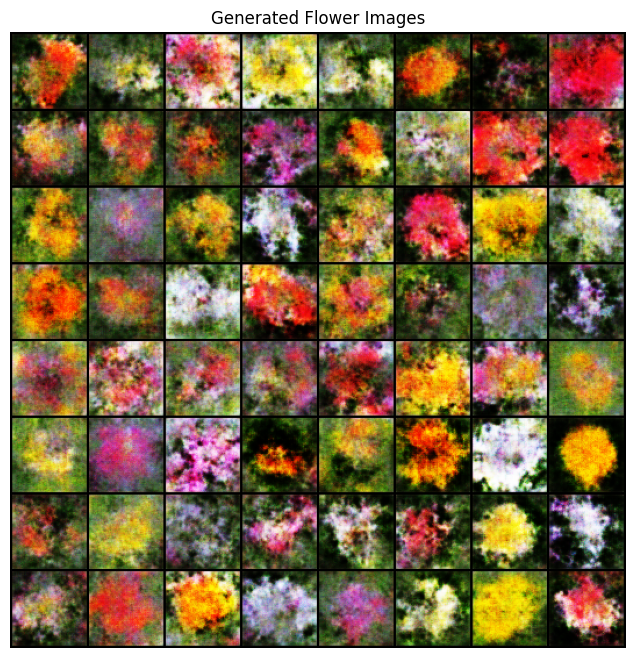

In [15]:
real_batch = next(iter(dataloader))
real_images = real_batch[0][:64].cpu()

with torch.no_grad():
    fake_images = generator(torch.randn(64, Z_DIM, 1, 1).to(device)).cpu()

real_grid = vutils.make_grid(denormalize(real_images), nrow=8, padding=2)
fake_grid = vutils.make_grid(denormalize(fake_images), nrow=8, padding=2)

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Real Flower Images")
plt.imshow(np.transpose(real_grid, (1, 2, 0)))
plt.show()

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Generated Flower Images")
plt.imshow(np.transpose(fake_grid, (1, 2, 0)))
plt.show()

# Task 17: Save the Trained Models



In [16]:
torch.save(generator.state_dict(), OUTPUT_DIR / "wgan_gp_generator_flowers102.pth")
torch.save(critic.state_dict(), OUTPUT_DIR / "wgan_gp_critic_flowers102.pth")

print("Saved generator to:", OUTPUT_DIR / "wgan_gp_generator_flowers102.pth")
print("Saved critic to:", OUTPUT_DIR / "wgan_gp_critic_flowers102.pth")


Saved generator to: wgan_gp_flowers_outputs/wgan_gp_generator_flowers102.pth
Saved critic to: wgan_gp_flowers_outputs/wgan_gp_critic_flowers102.pth


# Task 18: Reload the Generator and Generate Images



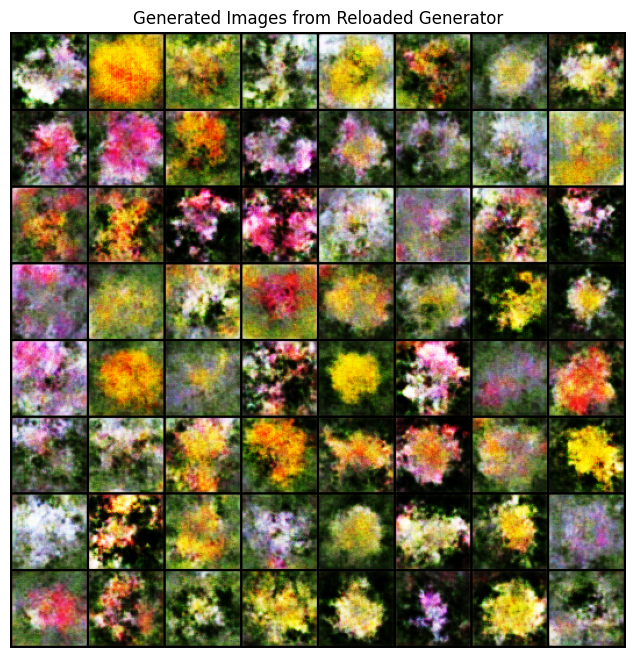

In [17]:
loaded_generator = Generator(Z_DIM, CHANNELS_IMG, FEATURES_G).to(device)
loaded_generator.load_state_dict(torch.load(OUTPUT_DIR / "wgan_gp_generator_flowers102.pth", map_location=device))
loaded_generator.eval()

with torch.no_grad():
    noise = torch.randn(64, Z_DIM, 1, 1).to(device)
    reloaded_samples = loaded_generator(noise).cpu()

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Generated Images from Reloaded Generator")
grid = vutils.make_grid(denormalize(reloaded_samples), nrow=8, padding=2)
plt.imshow(np.transpose(grid, (1, 2, 0)))
plt.show()